# Membrane voltage and changing gates

How can a short inward current trigger a much larger voltage excursion?

Fall 2024.


# Current, gates and a spike
Predict how the same-duration 2 and 10 µA/cm² pulses might differ. State the sign convention and distinguish current density from total current.

{'rest_mV': -69.89767289636794, 'rest_current_uA_cm2': 8.43769498715119e-15, 'weak_peak_mV': -68.26225810535843, 'strong_peak_mV': 33.96217211622026, 'gate_range': [0.013562699724249602, 0.9936018761583811], 'prescribed_charge_density_uA_ms_cm2': np.float64(9.999999999999975), 'gate_hand_example': 0.2348509478575048, 'voltage_refinement_max_gaps_mV': [0.020897983335209425, 0.005225064201106022], 'gap_ratio': 3.9995648916210094, 'invalid_cases_rejected': 4, 'runtime_seconds': 5.880951238796115}


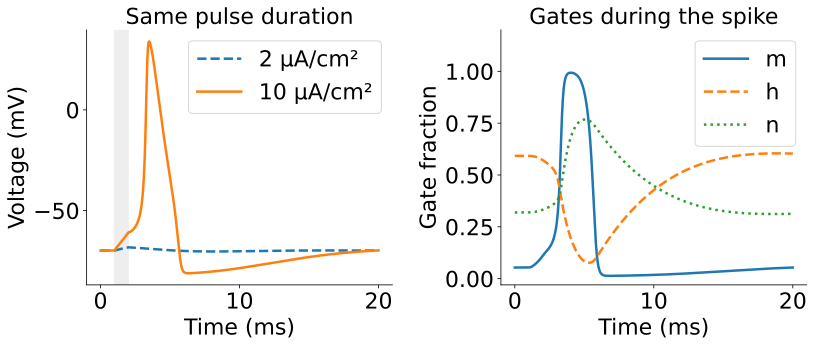

In [1]:
from demo import run, clamp
from membrane import simulate
from IPython.display import SVG, display
import numpy as np
result = run()
print(result)
display(SVG(filename='pulse-and-gates.svg'))

Interpret the onset, peak and recovery using conductance and driving difference. The pulse ends at 2 ms. Does the voltage stop changing at that instant?

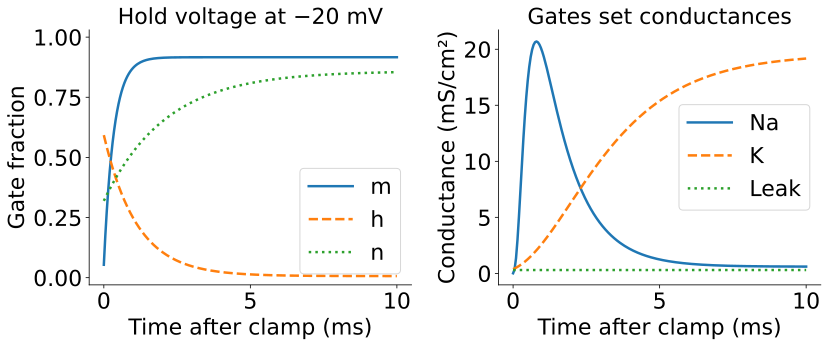

Clamped gate range: 0.006564041522807927 0.916324522639583


In [2]:
display(SVG(filename='voltage-clamp.svg'))
t, gates = clamp()
print('Clamped gate range:', gates.min(), gates.max())
assert np.all((gates >= 0) & (gates <= 1))

Modify: predict the response to a 5 µA/cm² pulse with the same timing. Then run it. This intermediate input is an exploration, not a proof of a universal threshold.

In [3]:
case = simulate(amplitude=5)
print('Peak (mV):', case['peak_mV'])
print('Delivered charge density (µA ms/cm²):', case['charge_uA_ms_cm2'])
assert abs(case['charge_uA_ms_cm2'] - 5) < 1e-12
print('Total current for area 0.02 cm² (µA):', 5*0.02)

Peak (mV): -65.69027513727988
Delivered charge density (µA ms/cm²): 4.999999999999988
Total current for area 0.02 cm² (µA): 0.1


Conclude: explain one difference between the clamp and pulse experiments. Name one numerical check and one independent observation needed to assess the model against biology.